# 02. Logistic Regression

Chọn cấu hình Logistic Regression bằng **5 fold dùng chung** trong `data/splits/splits.json`, fit cấu hình tốt nhất trên toàn bộ Train, rồi chấm một lần trên Validation.

**Đầu ra**

| Sản phẩm | Nơi lưu |
|---|---|
| Bảng CV | `reports/tables/logistic/cv_results.csv`, `cv_folds.csv` |
| Pipeline đã fit | `artifacts/logistic_pipeline.joblib` (kèm `.json` mô tả) |
| Điểm Validation | `reports/tables/logistic/validation_summary.csv`, `validation_per_class.csv` |
| Biểu đồ | `reports/figures/logistic/` |

Validation chỉ được dùng ở mục 8, sau khi cấu hình đã chốt, nên điểm báo cáo không bị chọn theo chính tập đó.

## Mở dữ liệu

Chọn kernel Python đã cài các thư viện trong `requirements.txt`.

In [1]:
import hashlib
import json
import os
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Tìm thư mục gốc để notebook đọc đúng file, kể cả khi kernel chạy từ thư mục con.
current = Path.cwd().resolve()
root = next(
    (folder for folder in (current, *current.parents)
     if (folder / "common/preprocessing.py").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở thư mục student-dropout-prediction trong VS Code rồi chạy notebook.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from common.preprocessing import FEATURE_COLUMNS, LABELS, TARGET, make_preprocessor
from common.metrics import (
    DROPOUT_LABEL, SUMMARY_COLUMNS, confusion_frame, evaluate, per_class_frame, summary_frame,
)

data_path = root / "data/raw/data.csv"
split_path = root / "data/splits/splits.json"
# File UCI ngăn cột bằng dấu chấm phẩy. Xóa khoảng trắng thừa quanh tên cột.
data = pd.read_csv(data_path, sep=";", encoding="utf-8-sig")
data.columns = data.columns.str.strip()

# Thống nhất ký tự xuống dòng trước khi tính mã nhận diện CSV trên Windows và Linux.
csv_bytes = data_path.read_bytes().replace(b"\r\n", b"\n")
data_hash = hashlib.sha256(csv_bytes).hexdigest()

table_dir = root / "reports/tables/logistic"
figure_dir = root / "reports/figures/logistic"
artifact_dir = root / "artifacts"
for folder in (table_dir, figure_dir, artifact_dir):
    folder.mkdir(parents=True, exist_ok=True)

## 1. Lấy Train, Validation và 5 fold dùng chung

Đọc bộ chia của notebook 00. Chỉ số trong file là số dòng của CSV gốc, trùng với index của `data`, nên lấy dòng bằng `.loc`.

In [2]:
if not split_path.is_file():
    raise FileNotFoundError("Chạy 00_prepare_data.ipynb để tạo bộ chia.")
split = json.loads(split_path.read_text(encoding="utf-8"))
if split["sha256"] != data_hash or split["n_rows"] != len(data):
    raise ValueError("CSV hiện tại khác bản dùng để tạo bộ chia.")

SEED = split["seed"]
FOLDS = split["folds"]
train_rows = split["train"]
validation_rows = split["validation"]

X = data[list(FEATURE_COLUMNS)]
y = data[TARGET]

# Năm fold phải nằm trọn trong Train. Nếu lệch thì việc chọn cấu hình đã chạm vào
# Validation và điểm ở mục 8 không còn là điểm của một tập giữ riêng.
train_set = set(train_rows)
for number, fold in enumerate(FOLDS, start=1):
    fit_rows, score_rows = set(fold["train"]), set(fold["validation"])
    if not fit_rows | score_rows <= train_set:
        raise ValueError(f"Fold {number} có dòng nằm ngoài Train.")
    if fit_rows & score_rows:
        raise ValueError(f"Fold {number} dùng chung dòng cho cả fit và chấm.")
if set(train_rows) & set(validation_rows):
    raise ValueError("Train và Validation bị chồng nhau.")

print(f"Train {len(train_rows):,} sinh viên — Validation {len(validation_rows):,} sinh viên")
print(f"{len(FOLDS)} fold dùng chung, mỗi lượt chấm khoảng {len(FOLDS[0]['validation']):,} sinh viên.")
display(
    pd.DataFrame({
        "train": y.loc[train_rows].value_counts().reindex(LABELS),
        "validation": y.loc[validation_rows].value_counts().reindex(LABELS),
    }).rename_axis("Target")
)

Train 3,096 sinh viên — Validation 664 sinh viên
5 fold dùng chung, mỗi lượt chấm khoảng 620 sinh viên.


,train,validation
Target,,
Dropout,995,213
Enrolled,556,119
Graduate,1545,332


## 2. Pipeline và lưới cấu hình

Mỗi lần fit tạo pipeline mới gồm **bộ tiền xử lý + Logistic Regression**. Đặt bộ tiền xử lý bên trong pipeline để trung vị, thang đo và danh sách mã one-hot chỉ học từ phần dữ liệu dùng để fit của lượt đó; phần chấm được transform bằng bộ đã fit. Logistic dùng `scale_numeric=True` vì phần phạt chỉ tác động đều lên các hệ số khi các cột số có cùng thang đo.

Ba thành phần được quét:

| Thành phần | Giá trị | Lý do quét |
|---|---|---|
| Phần phạt | `l2` (lbfgs), `l1` (saga), `elasticnet` l1_ratio 0.5 (saga) | khoảng 230 cột sau one-hot; `l1`/`elasticnet` có thể đưa hệ số về 0 |
| `C` | 0.01 → 10 (bảy mức, thang log) | `C` nhỏ là phạt mạnh; cần tìm mức vừa với lượng đặc trưng |
| `class_weight` | `None`, `balanced` | Train lệch lớp (Dropout 32%, Enrolled 18%, Graduate 50%) |

In [3]:
import sklearn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# scikit-learn 1.8 chuyển cách khai báo phần phạt từ penalty= sang l1_ratio=.
# requirements.txt cho phép từ 1.4 nên notebook chọn tham số theo bản đang chạy.
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
L1_RATIO = {"l2": 0.0, "l1": 1.0, "elasticnet": 0.5}


def penalty_kwargs(penalty):
    if SKLEARN_VERSION >= (1, 8):
        return {"l1_ratio": L1_RATIO[penalty]}
    if penalty == "elasticnet":
        return {"penalty": penalty, "l1_ratio": L1_RATIO[penalty]}
    return {"penalty": penalty}


# saga cần nhiều vòng lặp hơn lbfgs vì phải xử lý phần phạt L1.
MAX_ITER = {"lbfgs": 2000, "saga": 5000}


def make_logistic_pipeline(config):
    solver = config["solver"]
    model = LogisticRegression(
        C=config["C"],
        class_weight=config["class_weight"],
        solver=solver,
        max_iter=MAX_ITER[solver],
        random_state=SEED,
        **penalty_kwargs(config["penalty"]),
    )
    return Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=True)),
        ("model", model),
    ])


C_GRID = (0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0)
CLASS_WEIGHTS = (None, "balanced")
# lbfgs không hỗ trợ L1, nên hai phần phạt có L1 dùng saga.
PENALTY_SOLVERS = (("l2", "lbfgs"), ("l1", "saga"), ("elasticnet", "saga"))

grid = [
    {"penalty": penalty, "solver": solver, "C": C, "class_weight": class_weight}
    for penalty, solver in PENALTY_SOLVERS
    for C in C_GRID
    for class_weight in CLASS_WEIGHTS
]

config_frame = pd.DataFrame([
    {
        "config_id": config_id,
        "penalty": config["penalty"],
        "l1_ratio": L1_RATIO[config["penalty"]],
        "C": config["C"],
        "class_weight": config["class_weight"] or "none",
        "solver": config["solver"],
    }
    for config_id, config in enumerate(grid)
]).set_index("config_id")

print(f"scikit-learn {sklearn.__version__}")
print(f"{len(grid)} cấu hình × {len(FOLDS)} fold = {len(grid) * len(FOLDS)} lần fit.")
display(config_frame.head(4))

scikit-learn 1.9.0
42 cấu hình × 5 fold = 210 lần fit.


,penalty,l1_ratio,C,class_weight,solver
config_id,,,,,
0,l2,0.0,0.01,none,lbfgs
1,l2,0.0,0.01,balanced,lbfgs
2,l2,0.0,0.03,none,lbfgs
3,l2,0.0,0.03,balanced,lbfgs


## 3. Chạy 5-fold CV

Một lượt là: fit pipeline trên phần học của fold rồi chấm trên phần còn lại của fold đó. Mỗi cấu hình chạy đúng năm lượt trên cùng năm fold, nên các cấu hình được so trên cùng dữ liệu.

`n_iter` và `converged` được ghi lại để biết cấu hình nào chạm `max_iter` — điểm của những cấu hình đó là điểm của nghiệm chưa hội tụ.

In [4]:
from joblib import Parallel, delayed

CV_METRICS = ("macro_f1", "accuracy", "dropout_recall", "dropout_precision", "dropout_f2")
# saga chậm hơn lbfgs nhiều lần nên chia các lượt fit ra nhiều tiến trình.
N_JOBS = max(1, min(6, os.cpu_count() or 1))


def score_fold(config, fold):
    pipeline = make_logistic_pipeline(config)
    with warnings.catch_warnings():
        # Cấu hình chưa hội tụ vẫn được chấm; cột converged bên dưới ghi lại việc này.
        warnings.simplefilter("ignore", ConvergenceWarning)
        pipeline.fit(X.loc[fold["train"]], y.loc[fold["train"]])
    result = evaluate(y.loc[fold["validation"]], pipeline.predict(X.loc[fold["validation"]]))
    n_iter = int(np.max(pipeline["model"].n_iter_))
    return {
        **{metric: result[metric] for metric in CV_METRICS},
        "n_iter": n_iter,
        "converged": n_iter < MAX_ITER[config["solver"]],
    }


jobs = [
    (config_id, fold_number, config, fold)
    for config_id, config in enumerate(grid)
    for fold_number, fold in enumerate(FOLDS, start=1)
]

started = time.perf_counter()
records = Parallel(n_jobs=N_JOBS)(
    delayed(score_fold)(config, fold) for _, _, config, fold in jobs
)
print(f"{len(jobs)} lần fit trong {time.perf_counter() - started:.0f}s với {N_JOBS} tiến trình.")

fold_scores = pd.DataFrame([
    {"config_id": config_id, "fold": fold_number, **record}
    for (config_id, fold_number, _, _), record in zip(jobs, records)
])
fold_scores = config_frame.join(fold_scores.set_index("config_id")).reset_index()
fold_scores.to_csv(table_dir / "cv_folds.csv", index=False)
display(fold_scores.head())

210 lần fit trong 318s với 6 tiến trình.


,config_id,penalty,l1_ratio,C,class_weight,solver,fold,macro_f1,accuracy,dropout_recall,dropout_precision,dropout_f2,n_iter,converged
0,0,l2,0.0,0.01,none,lbfgs,1,0.617874,0.740323,0.753769,0.738916,0.750751,30,True
1,0,l2,0.0,0.01,none,lbfgs,2,0.642005,0.756058,0.758794,0.820652,0.770408,32,True
2,0,l2,0.0,0.01,none,lbfgs,3,0.658951,0.780291,0.829146,0.825000,0.828313,31,True
3,0,l2,0.0,0.01,none,lbfgs,4,0.614233,0.726979,0.753769,0.765306,0.756048,31,True
4,0,l2,0.0,0.01,none,lbfgs,5,0.680567,0.772213,0.768844,0.822581,0.779022,31,True


## 4. Bảng CV

Mỗi dòng là một cấu hình: trung bình và độ lệch chuẩn của Macro-F1 qua năm fold, kèm các metric còn lại để thấy cấu hình đó đổi gì giữa precision và recall của lớp Dropout.

In [5]:
cv_results = (
    fold_scores.groupby("config_id", sort=True)
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        accuracy_mean=("accuracy", "mean"),
        dropout_recall_mean=("dropout_recall", "mean"),
        dropout_precision_mean=("dropout_precision", "mean"),
        dropout_f2_mean=("dropout_f2", "mean"),
        n_iter_max=("n_iter", "max"),
        folds_converged=("converged", "sum"),
    )
)
cv_results = config_frame.join(cv_results)

# Macro-F1 là metric chính. Chênh lệch dưới 1e-4 giữa hai trung bình chỉ là nhiễu số học,
# nên làm tròn trước khi xếp hạng; nhờ vậy tiêu chí phụ mới thực sự được dùng khi bằng điểm:
# ưu tiên cấu hình ổn định hơn giữa các fold (std nhỏ), rồi mới xét F2 của lớp Dropout.
order = (
    pd.DataFrame({
        "macro_f1_rounded": cv_results["macro_f1_mean"].round(4),
        "macro_f1_std": cv_results["macro_f1_std"],
        "dropout_f2_mean": cv_results["dropout_f2_mean"],
    })
    .sort_values(["macro_f1_rounded", "macro_f1_std", "dropout_f2_mean"],
                 ascending=[False, True, False])
    .index
)
cv_results = cv_results.loc[order]
cv_results.to_csv(table_dir / "cv_results.csv")

not_converged = cv_results.loc[cv_results["folds_converged"] < len(FOLDS)]
print(f"{len(not_converged)}/{len(cv_results)} cấu hình có fold chạm max_iter.")
print("10 cấu hình đứng đầu theo Macro-F1 trung bình:")
display(cv_results.head(10).round(4))

0/42 cấu hình có fold chạm max_iter.
10 cấu hình đứng đầu theo Macro-F1 trung bình:


,penalty,l1_ratio,C,class_weight,solver,macro_f1_mean,macro_f1_std,accuracy_mean,dropout_recall_mean,dropout_precision_mean,dropout_f2_mean,n_iter_max,folds_converged
config_id,,,,,,,,,,,,,
7,l2,0.0,0.30,balanced,lbfgs,0.7180,0.0185,0.7571,0.7377,0.8419,0.7562,122,5
5,l2,0.0,0.10,balanced,lbfgs,0.7180,0.0186,0.7571,0.7327,0.8456,0.7526,77,5
3,l2,0.0,0.03,balanced,lbfgs,0.7166,0.0150,0.7565,0.7236,0.8361,0.7436,52,5
21,l1,1.0,0.30,balanced,saga,0.7154,0.0204,0.7552,0.7337,0.8342,0.7516,1186,5
35,elasticnet,0.5,0.30,balanced,saga,0.7152,0.0178,0.7549,0.7317,0.8342,0.7498,655,5
23,l1,1.0,1.00,balanced,saga,0.7137,0.0162,0.7526,0.7367,0.8370,0.7545,2827,5
33,elasticnet,0.5,0.10,balanced,saga,0.7113,0.0155,0.7516,0.7246,0.8331,0.7438,301,5
37,elasticnet,0.5,1.00,balanced,saga,0.7098,0.0149,0.7497,0.7357,0.8322,0.7529,1299,5
9,l2,0.0,1.00,balanced,lbfgs,0.7098,0.0190,0.7497,0.7407,0.8339,0.7574,130,5


### Nhận xét

Cả 42 cấu hình đều hội tụ trước `max_iter`, nên không có điểm nào là điểm của nghiệm dừng giữa đường.

**`class_weight` là yếu tố quyết định, không phải loại phần phạt.** Cấu hình `balanced` tốt nhất đạt Macro-F1 0.7180, cấu hình `none` tốt nhất chỉ 0.6944. Điều đáng chú ý là `none` lại có **accuracy cao hơn** (0.7716 so với 0.7571) và **recall Dropout cao hơn** (0.7749 so với 0.7427). Nguyên nhân: Enrolled chỉ chiếm 18% Train, khi không cân trọng số thì lớp này gần như không được dự đoán, F1 của nó rất thấp và kéo Macro-F1 xuống. `balanced` nhường một phần độ chính xác ở Dropout và Graduate để Enrolled được dự đoán, và Macro-F1 — vốn tính đều ba lớp — thưởng cho việc đó.

**Loại phần phạt gần như không tạo khác biệt.** Tại `C=0.3`, `class_weight=balanced`: L2 0.7180, L1 0.7154, ElasticNet 0.7152. Khoảng cách 0.003 nhỏ hơn nhiều so với std giữa các fold (~0.019), nên không thể kết luận phần phạt nào hơn. Nói cách khác, khoảng 230 cột sau one-hot không cần L1 để lọc bớt đặc trưng.

**`C` chỉ quan trọng ở vùng phạt mạnh.** Với L2 + `balanced`: C=0.01 cho 0.6944, C=0.03 lên 0.7166, C=0.1–0.3 đạt 0.7180, rồi giảm nhẹ còn 0.7049 ở C=10. Phạt quá mạnh làm mô hình thiếu linh hoạt; phạt quá nhẹ thì bắt đầu khớp nhiễu.

## 5. Cấu hình được chọn

Lấy dòng đầu của bảng CV đã sắp xếp. Đây là lựa chọn duy nhất được chốt từ CV; từ mục này trở đi lưới không được quét lại.

In [6]:
best_id = int(cv_results.index[0])
best_config = grid[best_id]
best_cv = cv_results.loc[best_id]

print("Cấu hình được chọn")
for field, value in best_config.items():
    print(f"  {field:14s} {value}")
print(f"  {'l1_ratio':14s} {L1_RATIO[best_config['penalty']]}")
print(f"  {'max_iter':14s} {MAX_ITER[best_config['solver']]}")
print(f"\nMacro-F1 CV: {best_cv['macro_f1_mean']:.4f} ± {best_cv['macro_f1_std']:.4f}")

# Điểm từng fold của cấu hình được chọn, để thấy mức dao động chứ không chỉ trung bình.
best_folds = (
    fold_scores.loc[fold_scores["config_id"].eq(best_id), ["fold", *CV_METRICS, "n_iter"]]
    .set_index("fold")
)
best_folds.to_csv(table_dir / "cv_best_folds.csv")
display(best_folds.round(4))

Cấu hình được chọn
  penalty        l2
  solver         lbfgs
  C              0.3
  class_weight   balanced
  l1_ratio       0.0
  max_iter       2000

Macro-F1 CV: 0.7180 ± 0.0185


,macro_f1,accuracy,dropout_recall,dropout_precision,dropout_f2,n_iter
fold,,,,,,
1,0.7066,0.7419,0.7286,0.7923,0.7406,122
2,0.7343,0.7706,0.7337,0.8957,0.7612,108
3,0.7416,0.7884,0.7638,0.8444,0.7787,108
4,0.7026,0.7431,0.7638,0.8398,0.7779,101
5,0.7046,0.7415,0.6985,0.8373,0.7225,112


## 6. Macro-F1 theo C

Xem ảnh hưởng của `C` và `class_weight` trên toàn lưới, không chỉ ở cấu hình thắng. Vùng đồ thị đi ngang cho biết điểm không còn nhạy với `C`, nên lựa chọn ít phụ thuộc vào một giá trị `C` cụ thể.

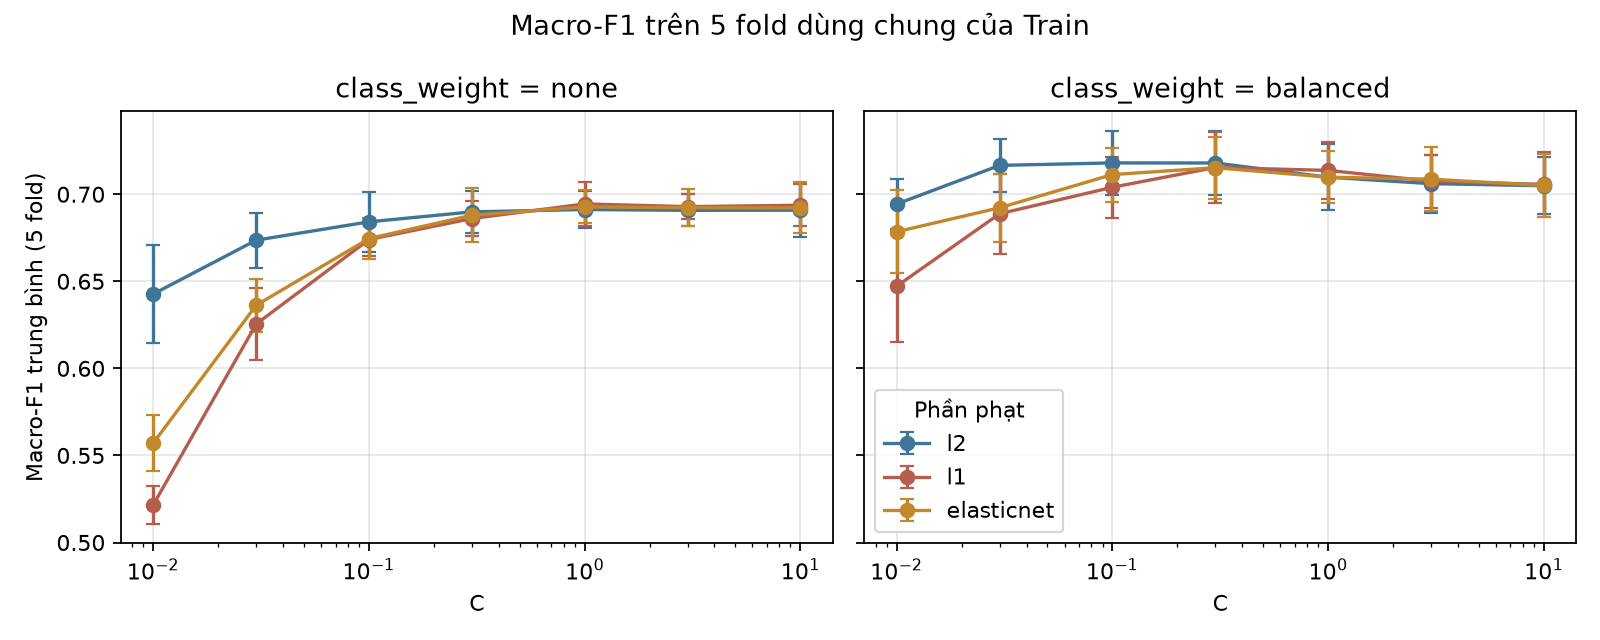

In [7]:
import matplotlib.pyplot as plt
from IPython.display import Image


def show_and_save(figure, filename):
    path = figure_dir / filename
    figure.tight_layout()
    figure.savefig(path, dpi=160)
    plt.close(figure)
    display(Image(filename=str(path)))


PENALTY_COLORS = {"l2": "#3F7599", "l1": "#B45F4D", "elasticnet": "#C3872C"}

figure, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, class_weight in zip(axes, ("none", "balanced")):
    for penalty in PENALTY_COLORS:
        line = cv_results.loc[
            cv_results["penalty"].eq(penalty) & cv_results["class_weight"].eq(class_weight)
        ].sort_values("C")
        ax.errorbar(
            line["C"], line["macro_f1_mean"], yerr=line["macro_f1_std"],
            marker="o", capsize=3, color=PENALTY_COLORS[penalty], label=penalty,
        )
    ax.set(xscale="log", xlabel="C", title=f"class_weight = {class_weight}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Macro-F1 trung bình (5 fold)")
axes[1].legend(title="Phần phạt")
figure.suptitle("Macro-F1 trên 5 fold dùng chung của Train")
show_and_save(figure, "cv_macro_f1.png")

### Nhận xét

Đồ thị tách rõ hai chuyện khác nhau.

**Trong vùng phạt nhẹ (`C` ≥ 0.3) ba đường của cùng một khung gần như trùng nhau** — loại phần phạt không còn tạo khác biệt, trong khi khoảng cách giữa hai khung vẫn giữ nguyên. Đây là bằng chứng bằng hình cho kết luận ở mục 4: `class_weight` mới là lựa chọn có ảnh hưởng, còn L1/L2/ElasticNet thì không.

**Ở vùng phạt mạnh (`C` ≤ 0.1) thì ngược lại, ba đường tách xa nhau.** Tại `C=0.01` khung `none`, L2 còn 0.6427 nhưng L1 tụt xuống 0.5217 và ElasticNet 0.5572. Lý do nằm ở cách hai phần phạt hoạt động: L1 đưa thẳng hệ số về 0 nên khi phạt mạnh nó cắt mất hẳn nhiều đặc trưng, còn L2 chỉ co hệ số lại và vẫn giữ toàn bộ. Vì vậy L1 nhạy với `C` hơn nhiều.

**Đỉnh không phải một điểm mà là một vùng phẳng**, với L2 + `balanced` trải từ `C=0.03` đến `C=0.3`. Thanh sai số (±1 std qua năm fold) của các điểm cạnh nhau chồng lên nhau gần hết, nên việc chọn `C=0.3` thay vì `C=0.1` hay `C=0.03` không dựa trên khác biệt có ý nghĩa thống kê — nó đến từ quy tắc chọn đã định trước ở mục 4. Đây là tín hiệu tốt: kết quả không treo vào một giá trị `C` may mắn.

Ở khung `none`, đường L2 đi lên rồi đi ngang từ `C=0.3` mà không giảm. Khi đó Enrolled đã bị bỏ gần hết, nên Macro-F1 bị chặn trên bởi chính việc lớp này không được dự đoán chứ không phải bởi mức phạt.

## 7. Fit trên toàn bộ Train và lưu pipeline

Fit lại cấu hình đã chọn trên cả 3,096 dòng Train. Bộ tiền xử lý trong pipeline lúc này học từ toàn bộ Train, nhiều dữ liệu hơn mỗi lượt CV.

Pipeline được lưu kèm một file `.json` ghi cấu hình, mã nhận diện CSV và điểm đạt được, để nhánh khác dùng lại mà không phải chạy lại notebook.

In [8]:
import joblib

best_pipeline = make_logistic_pipeline(best_config)
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    best_pipeline.fit(X.loc[train_rows], y.loc[train_rows])

final_model = best_pipeline["model"]
feature_names = best_pipeline["preprocess"].get_feature_names_out()
print(f"Fit trên {len(train_rows):,} dòng Train, {len(feature_names)} đặc trưng sau tiền xử lý.")
print(f"Thứ tự lớp của mô hình: {final_model.classes_.tolist()}")
print(f"Số vòng lặp: {np.max(final_model.n_iter_)} / {MAX_ITER[best_config['solver']]}")

pipeline_path = artifact_dir / "logistic_pipeline.joblib"
joblib.dump(best_pipeline, pipeline_path)

# Đọc lại file vừa lưu và so dự đoán, để chắc artifact bàn giao dùng được.
reloaded = joblib.load(pipeline_path)
if not np.array_equal(reloaded.predict(X.loc[validation_rows]),
                      best_pipeline.predict(X.loc[validation_rows])):
    raise ValueError("Pipeline đọc lại cho dự đoán khác bản vừa fit.")
print(f"Đã lưu {pipeline_path.relative_to(root)} "
      f"({pipeline_path.stat().st_size / 1024:.0f} KB) và kiểm tra đọc lại.")

Fit trên 3,096 dòng Train, 232 đặc trưng sau tiền xử lý.
Thứ tự lớp của mô hình: ['Dropout', 'Enrolled', 'Graduate']
Số vòng lặp: 124 / 2000
Đã lưu artifacts\logistic_pipeline.joblib (15 KB) và kiểm tra đọc lại.


## 8. Điểm trên Validation

Chấm một lần trên Validation 15% — tập chưa tham gia vào bước chọn cấu hình. Dummy `most_frequent` được fit trên cùng Train làm mốc tham chiếu tối thiểu; bảng so sánh chính thức giữa bốn phương pháp thuộc nhánh Dummy.

In [9]:
from sklearn.dummy import DummyClassifier

y_validation = y.loc[validation_rows]
validation_result = evaluate(y_validation, best_pipeline.predict(X.loc[validation_rows]))

reference = DummyClassifier(strategy="most_frequent").fit(X.loc[train_rows], y.loc[train_rows])
reference_result = evaluate(y_validation, reference.predict(X.loc[validation_rows]))

validation_summary = summary_frame({
    "Logistic Regression": validation_result,
    "Dummy (most_frequent)": reference_result,
})
validation_summary.to_csv(table_dir / "validation_summary.csv")

validation_per_class = per_class_frame(validation_result)
validation_per_class.to_csv(table_dir / "validation_per_class.csv")
confusion = confusion_frame(validation_result)
confusion.to_csv(table_dir / "validation_confusion.csv")

print(f"Validation: {validation_result['n_samples']:,} sinh viên")
print(f"Macro-F1  CV {best_cv['macro_f1_mean']:.4f} ± {best_cv['macro_f1_std']:.4f}"
      f"  →  Validation {validation_result['macro_f1']:.4f}")
display(validation_summary.round(4))
display(validation_per_class.round(4))
display(confusion)

Validation: 664 sinh viên
Macro-F1  CV 0.7180 ± 0.0185  →  Validation 0.6938


,accuracy,macro_f1,dropout_recall,dropout_precision,dropout_f2
model,,,,,
Logistic Regression,0.7319,0.6938,0.7418,0.802,0.7531
Dummy (most_frequent),0.5000,0.2222,0.0000,0.000,0.0000


,precision,recall,f1,f2,support
Dropout,0.8020,0.7418,0.7707,0.7531,213
Enrolled,0.4138,0.6050,0.4915,0.5538,119
Graduate,0.8737,0.7711,0.8192,0.7896,332


dự đoán,Dropout,Enrolled,Graduate
thực tế,,,
Dropout,158,41,14
Enrolled,24,72,23
Graduate,15,61,256


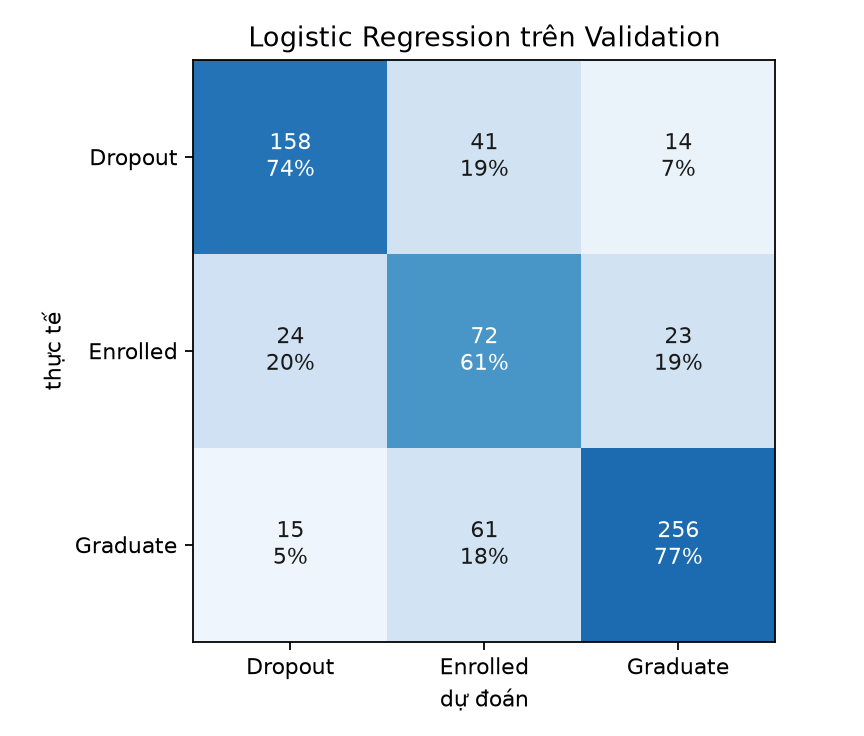

In [10]:
figure, ax = plt.subplots(figsize=(5.4, 4.6))
# Chia mỗi dòng cho support của dòng đó: màu thể hiện tỉ lệ trong từng lớp thực tế.
shares = confusion.to_numpy() / confusion.to_numpy().sum(axis=1, keepdims=True)
ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
for row in range(len(LABELS)):
    for column in range(len(LABELS)):
        count = confusion.to_numpy()[row, column]
        ax.text(column, row, f"{count}\n{shares[row, column]:.0%}",
                ha="center", va="center",
                color="white" if shares[row, column] > 0.5 else "#1A1A1A")
ax.set(xticks=range(len(LABELS)), yticks=range(len(LABELS)),
       xlabel="dự đoán", ylabel="thực tế",
       title="Logistic Regression trên Validation")
ax.set_xticklabels(LABELS)
ax.set_yticklabels(LABELS)
show_and_save(figure, "validation_confusion.png")

### Nhận xét

**Điểm bàn giao: Macro-F1 = 0.6938 trên Validation** (accuracy 0.7319, Dropout recall 0.7418, Dropout precision 0.8020, Dropout F2 0.7531).

**Validation thấp hơn CV 0.024, khoảng 1.3 lần std giữa các fold** — mức lệch nằm trong dao động bình thường, không phải dấu hiệu overfit nặng. Dù vậy vẫn có hai lý do khiến CV lạc quan hơn, cả hai nên ghi vào báo cáo:

1. Validation chỉ có 664 sinh viên và là **một** lần chia, nên bản thân con số đã có sai số lấy mẫu; CV lấy trung bình của năm lần chấm, phủ hết 3,096 dòng Train.
2. Điểm CV được báo cáo là **giá trị lớn nhất trong 42 cấu hình**, nên nó lạc quan hơn thực tế — khi chọn cực đại trên nhiều lựa chọn thì phần nhiễu có lợi cũng được chọn theo.

Vì vậy **0.6938 là con số nên dùng khi so sánh với các nhánh khác**, còn 0.7180 chỉ là căn cứ để chọn cấu hình.

**So với Dummy:** Macro-F1 0.2222 → 0.6938, accuracy 0.5000 → 0.7319, Dropout recall 0.0000 → 0.7418. Mô hình tuyến tính vượt baseline rõ rệt, và vượt ở cả lớp mà Dummy không bao giờ dự đoán.

**Enrolled là điểm yếu.** F1 từng lớp: Graduate 0.8192, Dropout 0.7707, Enrolled 0.4915. Enrolled có recall 0.6050 nhưng precision chỉ 0.4138 — trong 174 sinh viên được gán Enrolled chỉ 72 là đúng, còn lại là 41 Dropout và 61 Graduate bị kéo vào. Đây là hệ quả trực tiếp của `class_weight="balanced"`, và cũng phù hợp với bản chất bài toán: Enrolled là trạng thái trung gian, đặc trưng của nó nằm chen giữa hai lớp kia.

**Nhìn theo mục tiêu cảnh báo sớm:** mô hình nhận ra 158/213 sinh viên bỏ học (recall 0.7418). Trong 55 trường hợp bỏ sót, 41 bị gán Enrolled — vẫn là tín hiệu "chưa tốt nghiệp" nên nhà trường còn cơ hội để ý — và 14 bị gán Graduate. 14 trường hợp cuối là kiểu lỗi đáng lo nhất vì sinh viên có nguy cơ lại bị xem là an toàn.

## 9. Hệ số của mô hình

Logistic là mô hình tuyến tính nên đọc được hệ số. Cột số đã chuẩn hóa, vì vậy hệ số của nhóm `numeric__` so sánh được với nhau: hệ số dương làm tăng log-odds của lớp đó khi đặc trưng tăng một độ lệch chuẩn. Hệ số của cột one-hot và cột 0/1 nằm trên thang đo gốc nên không so trực tiếp với nhóm `numeric__`.

In [11]:
coefficients = pd.DataFrame(
    final_model.coef_.T, index=feature_names, columns=list(final_model.classes_),
)
coefficients.to_csv(table_dir / "coefficients.csv")

zero_everywhere = int(coefficients.abs().sum(axis=1).eq(0).sum())
print(f"Phần phạt {best_config['penalty']} (l1_ratio={L1_RATIO[best_config['penalty']]}): "
      f"{zero_everywhere}/{len(coefficients)} đặc trưng có hệ số 0 ở cả ba lớp.")

# Mười đặc trưng có |hệ số| lớn nhất cho lớp Dropout.
top_dropout = (
    coefficients[DROPOUT_LABEL]
    .sort_values(key=np.abs, ascending=False)
    .head(10)
    .rename(f"hệ số ({DROPOUT_LABEL})")
)
display(top_dropout.to_frame().round(4))

Phần phạt l2 (l1_ratio=0.0): 0/232 đặc trưng có hệ số 0 ở cả ba lớp.


,hệ số (Dropout)
binary__Tuition fees up to date,-1.5688
numeric__Curricular units 2nd sem (approved),-1.3648
categorical__Mother's occupation_0,0.8647
numeric__Curricular units 1st sem (approved),-0.8222
categorical__Mother's occupation_191,-0.7933
categorical__Father's occupation_90,0.7466
categorical__Course_9853,0.6510
numeric__Curricular units 2nd sem (enrolled),0.6273
categorical__Mother's qualification_12,0.6196
categorical__Course_9130,0.5956


In [12]:
metadata = {
    "model": "LogisticRegression",
    "created_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "notebook": "notebooks/models/logistic/02_logistic_regression.ipynb",
    "sklearn_version": sklearn.__version__,
    "data_sha256": data_hash,
    "split_seed": SEED,
    "labels": list(LABELS),
    "n_features_in": len(FEATURE_COLUMNS),
    "n_features_after_preprocess": int(len(feature_names)),
    "scale_numeric": True,
    "best_config": {
        **{key: value for key, value in best_config.items()},
        "l1_ratio": L1_RATIO[best_config["penalty"]],
        "max_iter": MAX_ITER[best_config["solver"]],
        "random_state": SEED,
    },
    "cross_validation": {
        "n_folds": len(FOLDS),
        "n_configs": len(grid),
        "selection_metric": "macro_f1",
        "macro_f1_mean": float(best_cv["macro_f1_mean"]),
        "macro_f1_std": float(best_cv["macro_f1_std"]),
    },
    "validation": {metric: float(validation_result[metric]) for metric in SUMMARY_COLUMNS},
}
metadata_path = pipeline_path.with_suffix(".json")
with metadata_path.open("w", encoding="utf-8", newline="\n") as output:
    json.dump(metadata, output, indent=2, ensure_ascii=False)
    output.write("\n")

print(f"Đã lưu {metadata_path.relative_to(root)}")
print(json.dumps(metadata["best_config"], ensure_ascii=False))
print(json.dumps(metadata["validation"], indent=2))

Đã lưu artifacts\logistic_pipeline.json
{"penalty": "l2", "solver": "lbfgs", "C": 0.3, "class_weight": "balanced", "l1_ratio": 0.0, "max_iter": 2000, "random_state": 42}
{
  "accuracy": 0.7319277108433735,
  "macro_f1": 0.6937997613696273,
  "dropout_recall": 0.7417840375586855,
  "dropout_precision": 0.8020304568527918,
  "dropout_f2": 0.7530981887511916
}


### Nhận xét

Hai đặc trưng có hệ số mạnh nhất cho Dropout trùng với những gì EDA đã thấy: `Tuition fees up to date` (−1.57; cột này ở thang 0/1 nên hệ số là toàn bộ khoảng cách giữa hai nhóm) và `Curricular units 2nd sem (approved)` (−1.36 cho mỗi độ lệch chuẩn). Dấu âm nghĩa là đã cập nhật học phí hoặc đậu nhiều học phần hơn thì log-odds vào lớp Dropout giảm.

Trong nhóm `numeric__`, các hệ số lớn nhất đều là biến kết quả học tập hai học kỳ đầu, và dấu của chúng ngược nhau một cách có ý nghĩa: số học phần **đậu** có hệ số âm (HK2 −1.36, HK1 −0.82) còn số học phần **đăng ký** có hệ số dương (HK2 +0.63). Đăng ký nhiều mà đậu ít chính là dấu hiệu rủi ro, và mô hình tuyến tính diễn tả được điều đó qua hiệu của hai biến.

Điều này cũng nhắc lại mốc dữ liệu của bài toán: mô hình đang dùng thông tin đến hết học kỳ 2, nên kết quả **không** diễn giải được thành "dự đoán ngay lúc nhập học".

Vì phần phạt được chọn là L2, không có đặc trưng nào bị đưa về 0 (0/232). Nếu báo cáo cần một mô hình gọn hơn để trình bày, cấu hình L1 `C=0.3 balanced` trong bảng CV chỉ kém 0.003 Macro-F1 và có thể dùng làm phương án rút gọn.

## Bàn giao

**Cấu hình đã chốt:** `LogisticRegression(penalty="l2", C=0.3, class_weight="balanced", solver="lbfgs", max_iter=2000, random_state=42)`, đặt sau `make_preprocessor(scale_numeric=True)` trong cùng một `Pipeline`.

| Sản phẩm | Đường dẫn |
|---|---|
| Notebook | `notebooks/models/logistic/02_logistic_regression.ipynb` |
| Bảng CV — 42 cấu hình | `reports/tables/logistic/cv_results.csv` |
| Bảng CV — từng fold | `reports/tables/logistic/cv_folds.csv`, `cv_best_folds.csv` |
| Pipeline đã fit | `artifacts/logistic_pipeline.joblib` |
| Mô tả artifact | `artifacts/logistic_pipeline.json` |
| Điểm Validation | `reports/tables/logistic/validation_summary.csv`, `validation_per_class.csv`, `validation_confusion.csv` |
| Hệ số | `reports/tables/logistic/coefficients.csv` |
| Biểu đồ | `reports/figures/logistic/cv_macro_f1.png`, `validation_confusion.png` |

**Điểm để đưa vào bảng so sánh bốn phương pháp:** Macro-F1 **0.6938** trên Validation (CV 0.7180 ± 0.0185 chỉ dùng để chọn cấu hình, không dùng để báo cáo).

**Dùng lại pipeline ở nhánh khác** — không cần chạy lại notebook:

```python
import joblib
from common.preprocessing import FEATURE_COLUMNS

pipeline = joblib.load("artifacts/logistic_pipeline.joblib")
predictions = pipeline.predict(df[list(FEATURE_COLUMNS)])          # nhãn chuỗi
probabilities = pipeline.predict_proba(df[list(FEATURE_COLUMNS)])  # thứ tự cột = pipeline["model"].classes_
```

Pipeline nhận DataFrame có đủ 36 cột đặc trưng với tên như trong CSV gốc (đã strip khoảng trắng) và tự làm phần tiền xử lý, nên nhánh khác không cần lặp lại bước scale hay one-hot.

**Tập Test chưa được dùng ở notebook này.** Theo quy ước của nhóm, Test chỉ mở một lần ở bước tổng hợp cuối giữa bốn phương pháp.